# Part 3: Question 2, Clustering Countries by Generation Mix

**Data science project: The Global Energy Transition Through Power Plants**

**Name:** Bernard Issifu

**Question 2.** Which groups of countries share similar electricity-generation mixes?

This notebook uses the prepared data from Part 1 (run `01_data_preparation_eda.ipynb` first). The R
version is `r/03_q2_clustering.Rmd`.

In [1]:
# ---- Setup ----
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, silhouette_samples, adjusted_rand_score

sns.set_theme(style="whitegrid")
pd.set_option("display.width", 140)
FIG_DIR = "../report/figures"
os.makedirs(FIG_DIR, exist_ok=True)

df = pd.read_csv("../data/processed/power_plants_clean_python.csv")
print(df.shape)

(34936, 15)


---
# 1. Approach

**Why it matters.** Countries start the energy transition from very different places: a country
running on hydro faces different choices from one running on coal or oil. Grouping countries by their
current mix shows which face similar challenges and could learn from each other.

**Country profiles.** For each country, the share of its total capacity in each of eight fuel groups:
Coal, Gas, Oil, Hydro, Nuclear, Wind, Solar and Other. Nuclear gets its own share here (unlike in
Question 1) because it is a large part of some countries' mix. Shares rather than gigawatts are used so
that a small country and a large country with the same mix look alike. Only countries with **at least
1 GW** of capacity are kept, because very small systems (a handful of plants) have unstable shares.

**Method.** **k-means** clustering on the eight shares. The shares are already on the same 0–1 scale, so
no standardization is needed. The number of clusters k is chosen with the **elbow** method (within-cluster
sum of squares) and the **silhouette** score (how much closer each country is to its own cluster than
to the next one; higher is better). k-means is run with 50 random starts. As a check, **hierarchical
clustering** (Ward linkage) is run with the same k and compared using the adjusted Rand index (ARI;
1 = identical groupings, 0 = no more agreement than chance).

In [2]:
mix_fuel = np.where(df["primary_fuel"] == "Nuclear", "Nuclear", df["fuel"])
cap = df.assign(mix=mix_fuel).pivot_table(index="country_long", columns="mix", values="capacity_mw",
                                          aggfunc="sum", fill_value=0)
total = cap.sum(axis=1)
shares = cap[total >= 1000].div(total[total >= 1000], axis=0)
shares = shares[["Coal", "Gas", "Oil", "Hydro", "Nuclear", "Wind", "Solar", "Other"]]
print(f"Countries with at least 1 GW: {len(shares)} of {len(cap)}")
print(f"They hold {total[total >= 1000].sum() / total.sum():.1%} of all capacity in the database")
shares.describe().round(3)

Countries with at least 1 GW: 120 of 167
They hold 99.7% of all capacity in the database


mix,Coal,Gas,Oil,Hydro,Nuclear,Wind,Solar,Other
count,120.000,120.000,120.000,120.000,120.000,120.000,120.000,120.000
mean,0.179,0.301,0.101,0.310,0.043,0.026,0.022,0.019
std,0.242,0.298,0.173,0.299,0.100,0.058,0.042,0.050
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.000,0.044,0.000,0.064,0.000,0.000,0.000,0.000
50%,0.055,0.223,0.017,0.200,0.000,0.000,0.003,0.000
75%,0.331,0.468,0.122,0.551,0.014,0.024,0.031,0.010
max,1.000,1.000,0.887,1.000,0.571,0.335,0.279,0.303


---
# 2. Choosing the number of clusters

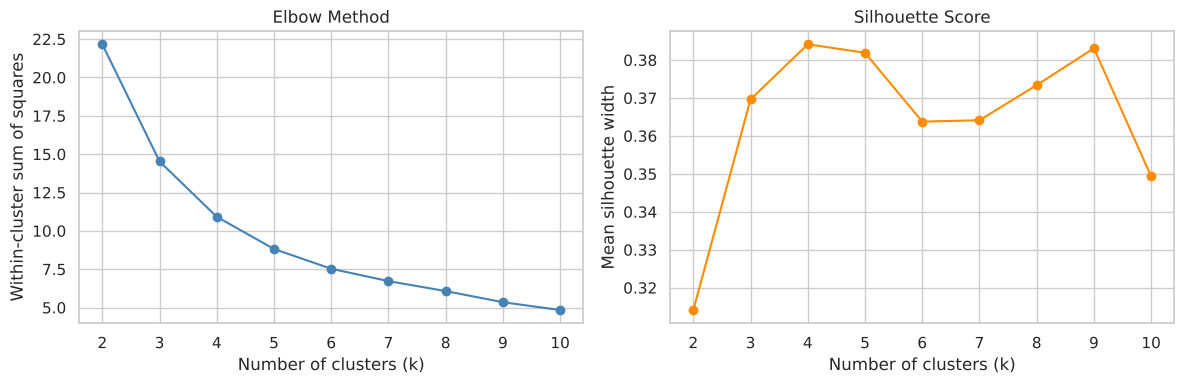

,inertia,silhouette
k,,
2,22.164,0.314
3,14.527,0.370
4,10.915,0.384
5,8.818,0.382
6,7.530,0.364
7,6.723,0.364
8,6.075,0.373
9,5.347,0.383
10,4.840,0.349


In [3]:
ks = range(2, 11)
scores = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(shares)
    scores.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(shares, km.labels_)})
scores = pd.DataFrame(scores).set_index("k")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(scores.index, scores["inertia"], marker="o", color="steelblue")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Within-cluster sum of squares")
axes[1].plot(scores.index, scores["silhouette"], marker="o", color="darkorange")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Mean silhouette width")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q2_choose_k.png", dpi=150)
plt.show()
scores.round(3)

**Interpretation.** The within-cluster sum of squares drops steeply up to k = 4 or 5 and more slowly
after that. The silhouette score is highest at k = 4 (0.384) and almost the same at k = 5 (0.382) and
k = 9 (0.383). I use **k = 5**: it scores essentially as well as k = 4, and the extra cluster separates
the oil-dominated countries from the gas-dominated ones, a distinction that matters for transition
planning. k = 9 would split 120 countries into groups too small to describe reliably.

---
# 3. The clusters

In [4]:
K = 5
km = KMeans(n_clusters=K, n_init=50, random_state=42).fit(shares)
labels = pd.Series(km.labels_, index=shares.index, name="cluster")
profile = shares.groupby(labels).mean()
profile["countries"] = labels.value_counts().sort_index()
profile["total_GW"] = (total.loc[shares.index].groupby(labels).sum() / 1000).round(0)
profile.round(2)

mix,Coal,Gas,Oil,Hydro,Nuclear,Wind,Solar,Other,countries,total_GW
cluster,,,,,,,,,,
0,0.05,0.10,0.05,0.74,0.02,0.01,0.00,0.02,32,494.0
1,0.04,0.78,0.04,0.09,0.01,0.01,0.03,0.00,25,415.0
2,0.66,0.05,0.01,0.19,0.06,0.02,0.02,0.00,18,2001.0
3,0.01,0.36,0.55,0.06,0.00,0.01,0.01,0.00,11,132.0
4,0.20,0.25,0.09,0.21,0.09,0.06,0.05,0.04,34,2648.0


In [5]:
# Name each cluster after its dominant fuels
def name_cluster(row):
    top = row[["Coal", "Gas", "Oil", "Hydro", "Nuclear", "Wind", "Solar", "Other"]].sort_values(
        ascending=False)
    if top.iloc[0] >= 0.5:
        return f"{top.index[0]}-dominated"
    return "Diversified" if top.iloc[0] < 0.3 else f"{top.index[0]} and {top.index[1]}"

names = profile.apply(name_cluster, axis=1)
labels_named = labels.map(names)
names.to_frame("cluster name")

,cluster name
cluster,
0,Hydro-dominated
1,Gas-dominated
2,Coal-dominated
3,Oil-dominated
4,Diversified


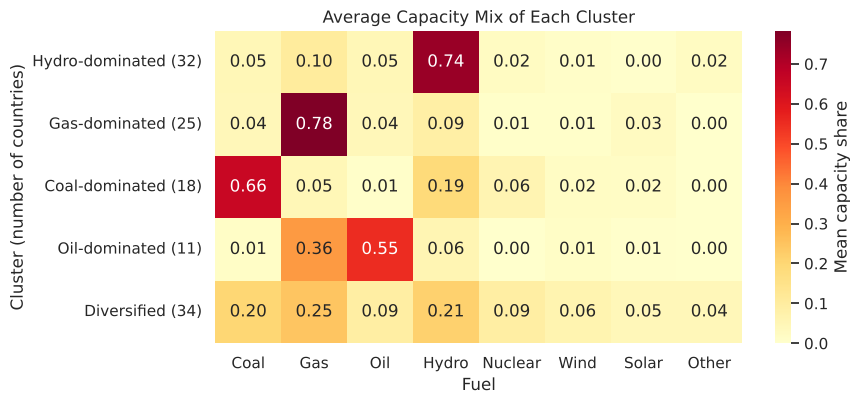

In [6]:
fig, ax = plt.subplots(figsize=(9, 4.2))
heat = profile[["Coal", "Gas", "Oil", "Hydro", "Nuclear", "Wind", "Solar", "Other"]].copy()
heat.index = [f"{names[i]} ({profile.loc[i, 'countries']})" for i in heat.index]
sns.heatmap(heat, annot=True, fmt=".2f", cmap="YlOrRd", cbar_kws={"label": "Mean capacity share"},
            ax=ax)
ax.set_title("Average Capacity Mix of Each Cluster")
ax.set_xlabel("Fuel")
ax.set_ylabel("Cluster (number of countries)")
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q2_cluster_profiles.png", dpi=150)
plt.show()

In [7]:
# Members of each cluster (largest countries first)
members = (pd.DataFrame({"cluster": labels_named, "GW": (total.loc[shares.index] / 1000).round(0)})
           .sort_values(["cluster", "GW"], ascending=[True, False]))
for name, grp in members.groupby("cluster"):
    print(f"{name} ({len(grp)}): " + ", ".join(grp.index[:15]) + (" ..." if len(grp) > 15 else ""))

Coal-dominated (18): China, India, South Africa, Indonesia, Ukraine, Poland, Kazakhstan, Czech Republic, Bulgaria, North Korea, Denmark, Serbia, Bosnia and Herzegovina, Moldova, Slovenia ...
Diversified (34): United States of America, Russia, Japan, Germany, France, South Korea, United Kingdom, Spain, Australia, Mexico, Turkey, Vietnam, Taiwan, Argentina, Malaysia ...
Gas-dominated (25): Italy, Iran, Thailand, Egypt, United Arab Emirates, Kuwait, Netherlands, Algeria, Israel, Singapore, Uzbekistan, Bangladesh, Qatar, Belarus, Bahrain ...
Hydro-dominated (32): Brazil, Canada, Norway, Venezuela, Sweden, Switzerland, Austria, Colombia, Paraguay, New Zealand, Laos, Tajikistan, Ecuador, Ethiopia, Georgia ...
Oil-dominated (11): Saudi Arabia, Iraq, Syrian Arab Republic, Azerbaijan, Cuba, Estonia, Turkmenistan, Dominican Republic, Lebanon, Cyprus, Yemen


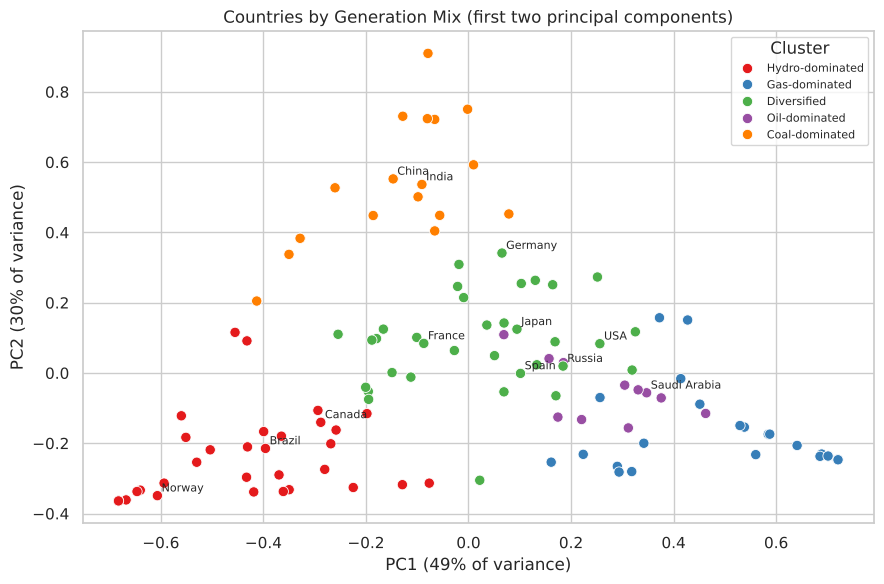

,PC1,PC2
mix,,
Coal,-0.09,0.79
Gas,0.71,-0.37
Oil,0.08,-0.04
Hydro,-0.69,-0.48
Nuclear,-0.01,0.07
Wind,-0.00,0.03
Solar,0.01,0.02
Other,-0.03,-0.01


In [8]:
# Two-dimensional view of the countries with principal component analysis (PCA)
pca = PCA(n_components=2).fit(shares)
coords = pd.DataFrame(pca.transform(shares), index=shares.index, columns=["PC1", "PC2"])
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=coords.assign(cluster=labels_named), x="PC1", y="PC2", hue="cluster", s=55,
                palette="Set1", ax=ax)
for country in ["China", "United States of America", "India", "Brazil", "France", "Germany",
                "Saudi Arabia", "Russia", "Canada", "Norway", "Spain", "Japan"]:
    if country in coords.index:
        ax.annotate(country.replace("United States of America", "USA"), coords.loc[country],
                    fontsize=8, xytext=(3, 3), textcoords="offset points")
ax.set_title("Countries by Generation Mix (first two principal components)")
ax.set_xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.0%} of variance)")
ax.legend(title="Cluster", fontsize=8)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/q2_pca_clusters.png", dpi=150)
plt.show()
pd.DataFrame(pca.components_.T, index=shares.columns, columns=["PC1", "PC2"]).round(2)

---
# 4. Checking the clusters

In [9]:
# Silhouette width by cluster
sil = pd.Series(silhouette_samples(shares, labels), index=shares.index)
sil.groupby(labels_named).agg(["mean", "min", "size"]).round(3)

,mean,min,size
cluster,,,
Coal-dominated,0.429,0.039,18
Diversified,0.149,-0.093,34
Gas-dominated,0.483,0.091,25
Hydro-dominated,0.490,0.122,32
Oil-dominated,0.481,0.207,11


In [10]:
# Hierarchical clustering (Ward linkage) with the same k
hc = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(shares)
print(f"Adjusted Rand index, k-means vs hierarchical: {adjusted_rand_score(labels, hc):.3f}")
pd.crosstab(labels_named, pd.Series(hc, index=shares.index, name="hierarchical cluster"))

Adjusted Rand index, k-means vs hierarchical: 0.623


hierarchical cluster,0,1,2,3,4
cluster,,,,,
Coal-dominated,0,18,0,0,0
Diversified,24,9,0,1,0
Gas-dominated,3,0,22,0,0
Hydro-dominated,3,2,0,27,0
Oil-dominated,0,0,2,0,9


In [11]:
members.to_csv(f"{FIG_DIR}/q2_country_clusters_python.csv")
profile.to_csv(f"{FIG_DIR}/q2_cluster_profiles_python.csv")
scores.to_csv(f"{FIG_DIR}/q2_k_selection_python.csv")

---
# 5. Discussion

**Five groups of countries.** Among the 120 countries with at least 1 GW (99.7% of the
database's capacity), k-means finds:

- **Hydro-dominated (32 countries, 494 GW):** on average 74% hydro, for example Brazil, Canada, Norway,
  Sweden, Switzerland, Colombia and Ethiopia. Their electricity is already largely low-carbon; their
  challenge is drought risk and meeting growing demand.
- **Coal-dominated (18 countries, 2,001 GW):** 66% coal on average, led by **China and India**, with
  South Africa, Indonesia, Poland and Ukraine. Few countries, but over a third of the capacity (35%) in
  the database and the largest decarbonization task.
- **Gas-dominated (25 countries, 415 GW):** 78% gas, mostly Middle Eastern and North African producers
  (Iran, Egypt, the UAE, Algeria, Qatar) plus Italy, the Netherlands and Thailand.
- **Oil-dominated (11 countries, 132 GW):** 55% oil and 36% gas, for example Saudi Arabia, Iraq, Cuba
  and Lebanon.
- **Diversified (34 countries, 2,648 GW):** no fuel above about 25% on average, including the United
  States, Russia, Japan, Germany, France, the United Kingdom and Spain. Wind (6%), solar (5%) and nuclear
  (9%) shares are highest here.

**How solid are the groups?** The four "dominated" clusters are compact (mean silhouette 0.43–0.49) and
hierarchical clustering reproduces them almost exactly. The diversified cluster is a looser catch-all
(mean silhouette 0.149); hierarchical clustering splits it, sending 9 of its 34 countries to the coal
group, which is the main reason the adjusted Rand index is 0.623 rather than close to 1. The PCA view
shows the structure: the first component (49% of the variance) runs from hydro to gas and the second
(30%) measures coal.

**No wind- or solar-led group.** No cluster is defined by wind or solar: their mean shares are only 2.6%
and 2.2%, and the highest single-country shares are 33.5% (wind) and 27.9% (solar). In this 2021
snapshot, the transition shows in new capacity (Part 1) more than in countries' overall mix.

**Limitations.** The mix is measured by **capacity, not generation**: a megawatt of solar produces far
less electricity per year than a megawatt of coal or nuclear. Coverage varies by country; for example,
Denmark appears coal-dominated (63% coal, 17% wind) because the database lists its large coal plants but
few of its many wind farms, and Estonia appears oil-dominated because oil-shale plants are recorded as
oil. The clusters describe the database's picture, which can lag behind reality.